# 5.5.5 — Embargos ambientais federais: tabelas, mapas e análise temporal

Este notebook acrescenta os complementos cartográficos e a **tabela completa por polígono de embargo**, mantendo a análise temporal e as quatro classificações já utilizadas no subcapítulo.

**Abra no Colab e escolha Ambiente de execução → Executar tudo.** Os caminhos dos arquivos do Drive já estão preenchidos. As entradas principais têm aproximadamente 18 MB cada; a leitura completa é adequada ao Colab, sem necessidade do cache de grandes arquivos usado em outras camadas. O cache é usado apenas para os limites do IBGE.

Produtos:
- Tabela integral dos polígonos e tabela dos 20 com mais registros, com glebas e referências distintas, áreas, valores e contagens temporais.
- Mapa geral com limites fortes, mapa da UF com mais registros e ampliação, e detalhes dos dois polígonos com mais registros.
- Mapa por classificação temporal e normativa, gráfico das quatro classes e gráfico anual da relação temporal.
- Tabelas por ano, produtor, UF, polígono e classe; lista dos registros prioritários; resultados municipais da V2 preservados.
- CSV, Excel, HTML, figuras em PNG 400 dpi/PDF/SVG, síntese e ZIP para preparar o Word.

**Resultados de referência, usados somente para conferir:** 931 registros; 626 glebas; 388 polígonos; 570 referências BACEN; 400 linhas com embargo anterior ou na mesma data e 531 com embargo posterior. As classes anteriores são 363 registros no período histórico, 29 no período identificado como Res. CMN 5.081/2023 e 8 no período identificado como Res. CMN 5.193/2024. Os 37 prioritários desde 02/01/2024 são conferidos em quantidade, área acumulada e valor somado.

**Nenhuma linha é excluída por repetição de REF_BACEN ou id_gleba2.** O identificador interno representa o polígono da base; não é necessariamente um termo, processo ou pessoa. A classificação existente é preservada literalmente e não constitui uma nova avaliação jurídica. A comparação das datas não confirma a vigência do embargo na contratação; a base temporal examinada não contém data de baixa ou suspensão que permita resolver essa questão. “Posterior” refere-se à data desse embargo registrado, sem afastar outras restrições.


## 1. Preparar o Colab

In [1]:
%pip -q install "geopandas>=1.0,<2" "shapely>=2.0,<3" "pyproj>=3.6" "pyogrio>=0.9" openpyxl matplotlib requests tqdm
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Caminhos da versão 2 e da análise temporal

As duas bases devem estar presentes: a V2 fornece as geometrias analíticas; o arquivo temporal fornece as datas tratadas e as classificações anteriores. Os arquivos municipais e estaduais preservam as comparações com o texto anterior. Os resultados serão salvos em uma nova pasta de execução, sem alterar as entradas.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
RAIZ=Path('/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios')
PASTA=RAIZ/'intersecoes'/'embargos'/'resultados_por_id_gleba2'
ARQUIVO_BASE=PASTA/'versao_2'/'bases_analiticas'/'base_registros_espaciais_sem_deduplicacao.csv'
ARQUIVO_TEMPORAL=PASTA/'analise_temporal_embargos'/'bases_analiticas'/'analise_temporal_embargos_classificada.csv'
ARQUIVO_MUNICIPIOS=PASTA/'versao_2'/'tabelas'/'09_resumo_por_municipio.csv'
ARQUIVO_UFS_V2=PASTA/'versao_2'/'tabelas'/'08_resumo_por_uf_espacial.csv'
ARQUIVO_UFS=None
ARQUIVO_BIOMAS=None
URL_UFS='https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2024/Brasil/BR_UF_2024.zip'
URL_BIOMAS='https://geoftp.ibge.gov.br/informacoes_ambientais/estudos_ambientais/biomas/vetores/Biomas_250mil.zip'
FONTE_UFS='IBGE, Malha de Unidades da Federação, 2024'
FONTE_BIOMAS='IBGE, Biomas do Brasil, 2019, escala 1:250.000'
COLUNA_UF='SIGLA_UF';COLUNA_BIOMA='Bioma'
CRS_WKT='EPSG:4674';CRS_ANALISE='EPSG:5880'
ANOS=[2021,2022,2023,2024,2025]
NUMERO_TERRITORIOS_DETALHE=2
SIMPLIFICACAO_GERAL_M=50;SIMPLIFICACAO_ESTADO_M=10
DPI=400;FORMATOS=['png','pdf','svg'];MOSTRAR_FIGURAS=True;BAIXAR_ZIP=True
TOLERANCIA_AREA_HA=0.05
# Referências servem para CONFERÊNCIA, nunca para substituir resultados calculados.
REFERENCIA=dict(registros=931,glebas=626,territorios=388,refs=570,
 area_acumulada_ha=25299.08729511092,area_uniao_ha=11122.343593090016,soma_valores_linhas=1392013462.24)
EXECUCAO=datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
SAIDA=RAIZ/'complementos_embargos_5_5_5'/EXECUCAO
CACHE=RAIZ/'complementos_embargos_5_5_5'/'_cache_contexto'
for p in [SAIDA,CACHE,SAIDA/'tabelas',SAIDA/'mapas',SAIDA/'graficos']:p.mkdir(parents=True,exist_ok=True)
print('Base espacial:',ARQUIVO_BASE)
print('Análise temporal preservada:',ARQUIVO_TEMPORAL)
print('Resultados:',SAIDA)


Base espacial: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/embargos/resultados_por_id_gleba2/versao_2/bases_analiticas/base_registros_espaciais_sem_deduplicacao.csv
Análise temporal preservada: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/embargos/resultados_por_id_gleba2/analise_temporal_embargos/bases_analiticas/analise_temporal_embargos_classificada.csv
Resultados: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_embargos_5_5_5/20260918_142715_010681


## 3. Ler as entradas e conferir o vínculo linha a linha

A junção usa `_ID_LINHA_ORIGINAL`, exigindo unicidade e o mesmo conjunto de linhas. Identificadores, datas originais e valores são confrontados antes da incorporação das classificações. Os identificadores são lidos como texto para preservar zeros. Não se usa REF_BACEN como chave única.

Os mapas e tabelas identificam os embargos por ID do polígono, número e série do termo. Nomes pessoais e documentos dos embargados não são incluídos nos produtos.

In [3]:
import csv as csvmod, json, hashlib, re, math, platform, textwrap, zipfile, unicodedata
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import box
from shapely.ops import transform as transformar
from pyproj import CRS, Transformer, Geod
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from IPython.display import display
from tqdm.auto import tqdm
csvmod.field_size_limit(2**31-1)
ORIGENS={}

def hash_arquivo(p):
 h=hashlib.sha256()
 with Path(p).open('rb') as f:
  for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
 return h.hexdigest()

def csv(t,n):
 t.to_csv(SAIDA/'tabelas'/n,index=False,sep=';',decimal=',',encoding='utf-8-sig',float_format='%.9f')

def numero_pt(v):
 s=str(v).strip()
 if s.lower() in ('','nan','none','null','<na>'):return np.nan
 if ',' in s:s=s.replace('.','').replace(',','.')
 f=float(s)
 if not np.isfinite(f):raise ValueError('Número não finito: '+s)
 return f

def ler_csv(p):
 p=Path(p)
 if not p.is_file():raise FileNotFoundError('Arquivo obrigatório não encontrado: '+str(p))
 with p.open(encoding='utf-8-sig',newline='') as f:
  reader=csvmod.reader(f,delimiter=';');head=next(reader)
  if len(head)!=len(set(head)):raise ValueError('Cabeçalho duplicado: '+str(p))
  rows=[]
  for i,r in enumerate(reader,2):
   if len(r)!=len(head):raise ValueError(f'Quantidade de campos divergente: {p.name}, linha {i}')
   rows.append(r)
 ORIGENS[p.name]={'arquivo':str(p),'bytes':p.stat().st_size,'sha256':hash_arquivo(p)}
 return pd.DataFrame(rows,columns=head)

base=ler_csv(ARQUIVO_BASE);temporal=ler_csv(ARQUIVO_TEMPORAL)
CAMINHO=ARQUIVO_BASE
C=dict(linha='_ID_LINHA_ORIGINAL',gleba='ID_GLEBA2',ref='REF_BACEN',ano='ANO_BASE',
 unidade='EMB_ID_INTERNO',nome='EMB_NOME_IMOVE',termo='EMB_NUM_TAD',serie='EMB_SERIE_TAD',
 uf_territorio='EMB_UF',municipio_atributo='EMB_MUNICIPIO',valor='VL_PARC_CREDITO',
 area_csv='AREA_INTERSECAO_HA',inter='GEOMETRIA_INTERSECAO_WKT',geom_gleba='GT_GEOMETRIA',
 geom_territorio='GEOMETRIA_EMBARGO_WKT',data_operacao_original='DT_EMISSAO',data_embargo_original='EMB_DAT_EMBARG',
 produtor_original='TIPO_PRODUTOR_ANALISE')
CT=dict(data_operacao='_DATA_OPERACAO',data_embargo='_DATA_EMBARGO',relacao_origem='_RELACAO_TEMPORAL',
 periodo_origem='_PERIODO_NORMATIVO',classe_origem='_CLASSIFICACAO_DISSERTACAO',
 encerramento_origem='_DATA_ENCERRAMENTO',vigencia_confirmada_origem='_VIGENCIA_CONFIRMADA',
 encerrado_antes_origem='_ENCERRADO_ANTES_OPERACAO',observacao_vigencia='_OBSERVACAO_VIGENCIA')
for d,cols,n in [(base,list(C.values()),'base espacial'),(temporal,list(CT.values())+['_ID_LINHA_ORIGINAL'],'análise temporal')]:
 faltam=set(cols)-set(d.columns)
 if faltam:raise ValueError(n+': colunas ausentes '+str(sorted(faltam)))
 ids=d['_ID_LINHA_ORIGINAL'].str.strip()
 if ids.eq('').any() or ids.duplicated().any():raise ValueError('ID de linha ausente ou repetido: '+n)
 d['_ID_LINHA_ORIGINAL']=ids
if set(base._ID_LINHA_ORIGINAL)!=set(temporal._ID_LINHA_ORIGINAL):
 raise ValueError('Universos de linhas diferentes entre a versão 2 e a análise temporal. Nenhuma junção parcial será feita.')
base=base.set_index('_ID_LINHA_ORIGINAL',drop=False)
temporal=temporal.set_index('_ID_LINHA_ORIGINAL',drop=False).loc[base.index]
# A classificação temporal só é vinculada depois de verificar identidade administrativa.
campos_identidade=['ID_GLEBA2','REF_BACEN','EMB_ID_INTERNO','ANO_BASE','DT_EMISSAO','EMB_DAT_EMBARG','VL_PARC_CREDITO']
controle_identidade=pd.DataFrame({'campo':campos_identidade,'divergencias':[(base[c].str.strip()!=temporal[c].str.strip()).sum() for c in campos_identidade]})
csv(controle_identidade,'conferencia_vinculo_temporal_v2.csv')
if controle_identidade.divergencias.any():raise ValueError('Atributos diferentes entre a base V2 e a análise temporal; veja a conferência.')
attrs=pd.DataFrame({k:base[c].str.strip() for k,c in C.items() if k not in ['inter','geom_gleba','geom_territorio']})
for k,c in CT.items():attrs[k]=temporal[c].str.strip()
for k in ['linha','gleba','ref','unidade','ano']:
 if attrs[k].str.lower().isin(['','nan','none','null','<na>']).any():raise ValueError('Identificador ausente: '+k)
for k in ['valor','area_csv']:attrs[k]=attrs[k].map(numero_pt)
if attrs[['valor','area_csv']].isna().any().any():raise ValueError('Há valores financeiros ou áreas ausentes; não serão substituídos por zero.')
attrs['ano']=attrs.ano.map(numero_pt).astype(int)
if not attrs.ano.isin(ANOS).all():raise ValueError('Ano fora do recorte 2021–2025.')
attrs['codigo_territorio']=attrs.unidade
attrs['nome_imovel_origem']=attrs.nome
attrs['nome']=['Polígono '+i+' · termo '+(t or 'não informado')+(('/'+s) if s else '') for i,t,s in zip(attrs.unidade,attrs.termo,attrs.serie)]
attrs['categoria_produtor']=attrs.produtor_original.str.strip()
print(f'{len(attrs)} linhas preservadas e vinculadas individualmente. Nenhuma deduplicação administrativa.')


931 linhas preservadas e vinculadas individualmente. Nenhuma deduplicação administrativa.


## 4. Preservar e conferir a análise temporal

Datas originais e tratadas são conferidas com formatos explícitos. A hora do embargo não é usada para inferir precedência dentro do mesmo dia. A comparação é por data civil: anterior ou mesma data, e posterior.

Os recortes de 02/01/2024 e 02/01/2025 são os empregados na análise anterior. Esta célula verifica a coerência entre datas e rótulos existentes; não atualiza a legislação, não determina a incidência das normas e não confirma vigência. Se houver divergência, exporta a auditoria e interrompe a execução, sem descartar linhas.

In [4]:
# Datas originais e datas já tratadas: formatos explícitos, sem inferência mês/dia.
def data_explicita(v):
 s=str(v).strip()
 if not s:return pd.NaT
 formatos=[(r'\d{4}-\d{2}-\d{2}','%Y-%m-%d'),
           (r'\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}','%Y-%m-%d %H:%M:%S'),
           (r'\d{2}/\d{2}/\d{4}','%d/%m/%Y'),
           (r'\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2}','%d/%m/%Y %H:%M:%S'),
           (r'\d{2}/\d{2}/\d{2} \d{2}:\d{2}:\d{2}','%d/%m/%y %H:%M:%S')]
 for pattern,fmt in formatos:
  if re.fullmatch(pattern,s):return pd.to_datetime(s,format=fmt,errors='coerce').normalize()
 return pd.NaT
for c in ['data_operacao','data_embargo','data_operacao_original','data_embargo_original']:
 attrs[c+'_lida']=attrs[c].map(data_explicita)
qualidade_datas=attrs[['linha','unidade','ref','data_operacao','data_embargo','data_operacao_original','data_embargo_original']].copy()
qualidade_datas['datas_validas']=attrs[[c+'_lida' for c in ['data_operacao','data_embargo','data_operacao_original','data_embargo_original']]].notna().all(axis=1)
qualidade_datas['operacao_confere']=attrs.data_operacao_lida.eq(attrs.data_operacao_original_lida)
qualidade_datas['embargo_confere']=attrs.data_embargo_lida.eq(attrs.data_embargo_original_lida)
qualidade_datas['ano_confere']=attrs.data_operacao_lida.dt.year.eq(attrs.ano)
csv(qualidade_datas,'auditoria_datas_por_linha.csv')
if not qualidade_datas.iloc[:,-4:].all().all():raise ValueError('Problema nas datas; veja auditoria_datas_por_linha.csv. Nenhuma linha foi descartada.')
attrs['ano_operacao']=attrs.data_operacao_lida.dt.year
attrs['dias_entre_embargo_e_operacao']=(attrs.data_operacao_lida-attrs.data_embargo_lida).dt.days
attrs['mesma_data']=attrs.dias_entre_embargo_e_operacao.eq(0)
ANT='Embargo anterior ou na mesma data';POST='Embargo posterior'
attrs['relacao_temporal']=np.where(attrs.dias_entre_embargo_e_operacao.ge(0),ANT,POST)
# As quatro classificações abaixo são as já existentes no arquivo temporal.
CLASSES=[
 'Embargo posterior à contratação',
 'Embargo anterior — verificar regra histórica e vigência',
 'Embargo anterior no período da Res. CMN nº 5.081/2023 — verificar vigência e exceções',
 'Embargo anterior no período da Res. CMN nº 5.193/2024 — verificar vigência e exceções']
ROTULOS_CURTOS=['Posterior à operação','Anterior/mesma data\nRegra histórica',
 'Anterior/mesma data\nPeríodo 5.081/2023','Anterior/mesma data\nPeríodo 5.193/2024']
CORES_CLASSES=['#087E8B','#B07818','#C34335','#6B3D8F']
if not attrs.classe_origem.isin(CLASSES).all():raise ValueError('Há classificação não prevista; confira a análise temporal original.')
rel_origem=attrs.relacao_origem.str.lower()
controle_temporal=attrs[['linha','relacao_origem','relacao_temporal','periodo_origem','classe_origem']].copy()
controle_temporal['relacao_confere']=np.where(attrs.relacao_temporal.eq(POST),rel_origem.str.contains('posterior'),rel_origem.str.contains('anterior|mesma data'))
# Confere compatibilidade com os recortes que a análise anterior efetivamente utilizou.
# Não é uma nova determinação de aplicabilidade jurídica das normas.
op=attrs.data_operacao_lida
classe_esperada=np.select([attrs.relacao_temporal.eq(POST),op.lt(pd.Timestamp('2024-01-02')),op.lt(pd.Timestamp('2025-01-02'))],CLASSES[:3],default=CLASSES[3])
controle_temporal['classe_confere']=attrs.classe_origem.eq(classe_esperada)
csv(controle_temporal,'conferencia_classificacao_temporal_preservada.csv')
if not controle_temporal[['relacao_confere','classe_confere']].all().all():raise ValueError('Classificação original incompatível com as datas. Revise antes de produzir as figuras.')
attrs['classificacao']=attrs.classe_origem # preservada literalmente, não substituída
attrs['prioritario']=attrs.relacao_temporal.eq(ANT)&op.ge(pd.Timestamp('2024-01-02'))
attrs['encerramento_informado']=attrs.encerramento_origem.ne('')
# False em vigência confirmada significa que não houve confirmação; NÃO significa embargo inativo.
qualidade_temporal=pd.DataFrame({'indicador':['Linhas com datas válidas','Embargo na mesma data','Linhas com data de encerramento informada','Linhas com vigência confirmada no arquivo de origem'],
 'quantidade':[int(qualidade_datas.datas_validas.sum()),int(attrs.mesma_data.sum()),int(attrs.encerramento_informado.sum()),int(attrs.vigencia_confirmada_origem.str.lower().eq('true').sum())]})
csv(qualidade_temporal,'qualidade_temporal.csv');display(qualidade_temporal)
print('Classificações preservadas. Ordem temporal não comprova vigência, impedimento ou irregularidade.')


,indicador,quantidade
0,Linhas com datas válidas,931
1,Embargo na mesma data,0
2,Linhas com data de encerramento informada,0
3,Linhas com vigência confirmada no arquivo de o...,0


Classificações preservadas. Ordem temporal não comprova vigência, impedimento ou irregularidade.


## 5. Validar geometrias e calcular áreas

A fonte das geometrias de interseção é a V2. O arquivo temporal pode conter `GeometryCollection`, com polígonos, linhas e pontos; na comparação entre arquivos, somente os componentes poligonais são comparados. Isso não exclui linhas administrativas nem altera a classificação temporal. Eventuais tratamentos dessa cópia ficam documentados na auditoria; ela nunca substitui a geometria analítica.

Reparos após reprojeção são permitidos somente para os limites de embargo e gleba destinados ao desenho e ficam registrados. As interseções analíticas permanecem sob validação rigorosa. A simplificação é exclusiva do desenho geral e estadual; os mapas de detalhe utilizam os limites integrais.

In [5]:
converter=Transformer.from_crs(CRS_WKT,CRS_ANALISE,always_xy=True).transform
REPAROS_CARTOGRAFICOS=[]
def poligono(wkt,identificacao,desenho=False):
 g=shapely.force_2d(shapely.from_wkt(wkt))
 if g is None or g.is_empty or g.geom_type not in ['Polygon','MultiPolygon'] or not g.is_valid:
  raise ValueError('Geometria de origem ausente, inválida ou não poligonal: '+identificacao)
 a,b,c,d=g.bounds
 if not np.isfinite([a,b,c,d]).all():raise ValueError('Coordenadas não finitas: '+identificacao)
 if CRS.from_user_input(CRS_WKT).is_geographic and not (-80<a<-30 and -40<b<10 and -80<c<-30 and -40<d<10):
  raise ValueError('Coordenadas incompatíveis com o CRS geográfico: '+identificacao)
 g=transformar(converter,g)
 if not g.is_valid:
  if not desenho:raise ValueError('Interseção inválida após reprojeção: '+identificacao)
  antes=g.area/10000;motivo=shapely.is_valid_reason(g);g=shapely.make_valid(g)
  def partes_poligonais(z):
   if z.geom_type=='Polygon':return [z]
   if hasattr(z,'geoms'):return [p for sub in z.geoms for p in partes_poligonais(sub)]
   return []
  partes=partes_poligonais(g)
  if not partes:raise ValueError('Reparo sem componente poligonal: '+identificacao)
  g=shapely.union_all(partes)
  REPAROS_CARTOGRAFICOS.append({'identificacao':identificacao,'motivo':motivo,'area_antes_ha':antes,'area_depois_ha':g.area/10000})
 if g.is_empty or not g.is_valid or not np.isfinite(g.area) or g.area<=0:raise ValueError('Geometria problemática após projeção: '+identificacao)
 return g

geoms=[];conferencia_copias=[]
for ident,r in tqdm(base.iterrows(),total=len(base),desc='Validando interseções'):
 g=poligono(r[C['inter']],'interseção '+ident)
 # A V2 é a fonte geométrica analítica. A cópia temporal é usada apenas na auditoria.
 gt0=shapely.force_2d(shapely.from_wkt(temporal.loc[ident,C['inter']]))
 if gt0 is None or gt0.is_empty:raise ValueError('Cópia temporal ausente: '+ident)
 copia_valida_origem=bool(gt0.is_valid)
 tipo_copia=gt0.geom_type
 def componentes_poligonais(z):
  if z.geom_type=='Polygon':return [z]
  if hasattr(z,'geoms'):return [p for sub in z.geoms for p in componentes_poligonais(sub)]
  return []
 partes_copia=componentes_poligonais(gt0)
 if not partes_copia:raise ValueError('Cópia temporal sem área poligonal: '+ident)
 gt=transformar(converter,shapely.union_all(partes_copia));copia_valida_projetada=bool(gt.is_valid)
 if not gt.is_valid:gt=shapely.make_valid(gt) # somente comparação; nunca substitui g
 if gt.is_empty:raise ValueError('Cópia temporal vazia após tratamento para comparação: '+ident)
 igual=g.equals(gt);dif=0.0 if igual else g.symmetric_difference(gt).area/10000
 distancia=0.0 if igual else g.hausdorff_distance(gt)
 conferencia_copias.append({'linha':ident,'tipo_copia_temporal':tipo_copia,'copia_temporal_valida_origem':copia_valida_origem,'copia_temporal_valida_projetada':copia_valida_projetada,'iguais_topologicamente':igual,'diferenca_simetrica_ha':dif,'distancia_hausdorff_m':distancia,
  'compativeis':igual or (dif<=1e-6 and distancia<=0.001)})
 geoms.append(g)
conferencia_copias=pd.DataFrame(conferencia_copias);csv(conferencia_copias,'conferencia_geometrias_v2_versus_temporal.csv')
if not conferencia_copias.compativeis.all():raise ValueError('Interseções diferentes entre a V2 e a análise temporal. Confira a auditoria.')
x=gpd.GeoDataFrame(attrs.reset_index(drop=True),geometry=geoms,crs=CRS_ANALISE)
x['area_ha']=x.geometry.area/10000
area_check=x[['linha','unidade','gleba','area_csv','area_ha']].copy();area_check['diferenca_ha']=area_check.area_ha-area_check.area_csv
csv(area_check,'conferencia_areas_por_linha.csv')
if area_check.diferenca_ha.abs().max()>TOLERANCIA_AREA_HA:raise ValueError('Área diverge da fonte; confira CRS e auditoria.')
# Reúne cópias somente para desenhar. Todas as linhas de x permanecem nas estatísticas.
colecoes={}
for tipo,key,col,campos in [('territorio','unidade',C['geom_territorio'],['unidade','nome','nome_imovel_origem','termo','serie','uf_territorio','municipio_atributo','data_embargo']),
                            ('gleba','gleba',C['geom_gleba'],['gleba'])]:
 rows=[]
 for ident,z in tqdm(attrs.groupby(key,sort=False),desc='Limites '+tipo):
  for c in campos:
   if z[c].nunique(dropna=False)!=1:raise ValueError(f'Atributo {c} divergente para {tipo} {ident}')
  wkts=base.loc[z.index,col].unique();g=poligono(wkts[0],tipo+'='+ident,desenho=True)
  for w in wkts[1:]:
   if not g.equals(poligono(w,tipo+'='+ident,desenho=True)):raise ValueError('Cópias territoriais divergentes: '+ident)
  rows.append({**z.iloc[0][campos].to_dict(),'geometry':g})
 colecoes[tipo]=gpd.GeoDataFrame(rows,geometry='geometry',crs=CRS_ANALISE)

def carregar_geometrias(tipo,ids=None,simplificar=0):
 z=colecoes[tipo].copy();campo='unidade' if tipo=='territorio' else 'gleba'
 if ids is not None:z=z.loc[z[campo].isin(set(map(str,ids)))].copy()
 if simplificar:z.geometry=z.geometry.simplify(simplificar,preserve_topology=True)
 return z
territorios=carregar_geometrias('territorio',simplificar=SIMPLIFICACAO_GERAL_M)
glebas=carregar_geometrias('gleba',simplificar=SIMPLIFICACAO_GERAL_M)
reparos=pd.DataFrame(REPAROS_CARTOGRAFICOS,columns=['identificacao','motivo','area_antes_ha','area_depois_ha'])
csv(reparos,'reparos_exclusivos_desenho.csv')
print(f'{len(x)} linhas; {len(glebas)} glebas; {len(territorios)} polígonos de embargo. Reparos de desenho: {len(reparos)}.')


Validando interseções:   0%|          | 0/931 [00:00<?, ?it/s]

Limites territorio:   0%|          | 0/388 [00:00<?, ?it/s]

Limites gleba:   0%|          | 0/626 [00:00<?, ?it/s]

931 linhas; 626 glebas; 388 polígonos de embargo. Reparos de desenho: 0.


## 6. Totais por polígono e manutenção das tabelas temporais

Registros contam linhas; glebas e referências são distintas dentro de cada grupo. A área acumulada soma as linhas e a união é recalculada em cada grupo. Contagens distintas e uniões de grupos não são aditivas. Valores financeiros não são deduplicados nem rateados pela área intersectada.

A tabela por polígono é consolidada diretamente pelo `EMB_ID_INTERNO`. Categorias de produtor não são interpretadas como tipo de embargo. Os dois polígonos para detalhe são selecionados pelo número de registros, com desempate por rótulo e ID.

In [6]:
def metricas(z):
 return dict(registros=len(z),glebas=z.gleba.nunique(),territorios=z.unidade.nunique(),refs=z.ref.nunique(),
  area_acumulada_ha=float(z.area_ha.sum()),area_uniao_ha=float(z.geometry.union_all().area/10000) if len(z) else 0.,
  soma_valores_linhas=float(z.valor.sum()))
def agrupar(z,campos):
 if isinstance(campos,str):campos=[campos]
 rows=[]
 for ks,g in z.groupby(campos,dropna=False,sort=True):
  if not isinstance(ks,tuple):ks=(ks,)
  rows.append({**dict(zip(campos,ks)),**metricas(g)})
 return pd.DataFrame(rows)
geral=metricas(x);csv(pd.DataFrame([geral]),'totais_gerais.csv')
conferencia=pd.DataFrame([{'indicador':k,'esperado':v,'calculado':geral[k],'confere':abs(geral[k]-v)<=(TOLERANCIA_AREA_HA if 'area_' in k else 0.02 if k=='soma_valores_linhas' else 0)} for k,v in REFERENCIA.items()])
csv(conferencia,'conferencia_totais_com_subcapitulo.csv')
if not conferencia.confere.all():display(conferencia);raise ValueError('Os totais diferem do subcapítulo; confira a origem antes de seguir.')
por_territorio=agrupar(x,'unidade').merge(colecoes['territorio'].drop(columns='geometry'),on='unidade',validate='one_to_one')
cont=x.groupby(['unidade','relacao_temporal']).size().unstack(fill_value=0).reindex(columns=[ANT,POST],fill_value=0).reset_index().rename(columns={ANT:'registros_anterior_ou_mesma_data',POST:'registros_posterior'})
por_territorio=por_territorio.merge(cont,on='unidade',validate='one_to_one')
prior_por=x.groupby('unidade').prioritario.sum().rename('registros_prioritarios_desde_2024').reset_index()
por_territorio=por_territorio.merge(prior_por,on='unidade',validate='one_to_one')
por_territorio=por_territorio.sort_values(['registros','nome','unidade'],ascending=[False,True,True]).reset_index(drop=True)
por_territorio.insert(0,'posicao',np.arange(1,len(por_territorio)+1))
csv(por_territorio,'totais_por_poligono_embargo_completo.csv');csv(por_territorio.head(20),'20_poligonos_com_mais_registros.csv')
TOP_TERRITORIOS=por_territorio.head(NUMERO_TERRITORIOS_DETALHE).unidade.tolist()
por_relacao=agrupar(x,'relacao_temporal');por_classe=agrupar(x,'classificacao')
por_classe['ordem']=por_classe.classificacao.map({v:i for i,v in enumerate(CLASSES)})
por_classe=por_classe.sort_values('ordem').drop(columns='ordem')
por_ano=agrupar(x,'ano_operacao');por_ano_relacao=agrupar(x,['ano_operacao','relacao_temporal'])
por_ano_classe=agrupar(x,['ano_operacao','classificacao'])
por_produtor=agrupar(x,'categoria_produtor');por_produtor_classe=agrupar(x,['categoria_produtor','classificacao'])
por_embargo_classe=agrupar(x,['unidade','classificacao'])
matriz=pd.crosstab(x.ano_operacao,x.relacao_temporal).reindex(index=ANOS,columns=[ANT,POST],fill_value=0)
matriz.index.name='ano_operacao'
esperada=pd.DataFrame({ANT:[187,108,68,29,8],POST:[242,117,92,59,21]},index=ANOS)
conferencia_matriz=matriz.reset_index().copy();conferencia_matriz['confere']=(matriz.to_numpy()==esperada.to_numpy()).all(axis=1)
csv(conferencia_matriz,'conferencia_matriz_anual.csv')
if not conferencia_matriz.confere.all():raise ValueError('Relação temporal anual diverge da análise anterior.')
controle_classes=por_classe.copy();controle_classes['registros_referencia']=[531,363,29,8]
controle_classes['valor_referencia']=[791503965.48,481591203.96,91860845.39,27057447.41]
controle_classes['confere']=controle_classes.registros.eq(controle_classes.registros_referencia)&(controle_classes.soma_valores_linhas-controle_classes.valor_referencia).abs().le(.02)
csv(controle_classes,'conferencia_quatro_classificacoes.csv')
if not controle_classes.confere.all():raise ValueError('Classes ou valores divergem da análise anterior.')
prioritarios=x.loc[x.prioritario].copy();resumo_prioritarios=metricas(prioritarios)
controle_prioritarios=pd.DataFrame([{'indicador':k,'referencia':v,'calculado':resumo_prioritarios[k],
 'confere':abs(resumo_prioritarios[k]-v)<=(.05 if 'area' in k else .02 if 'valor' in k else 0)}
 for k,v in {'registros':37,'area_acumulada_ha':1532.4131938798798,'soma_valores_linhas':118918292.80}.items()])
csv(controle_prioritarios,'conferencia_37_prioritarios.csv')
if not controle_prioritarios.confere.all():raise ValueError('Os registros prioritários diferem da referência.')
# Exportação analítica enxuta, mantendo todas as linhas e a identificação original.
campos_linhas=['linha','unidade','nome','termo','serie','gleba','ref','ano_operacao','categoria_produtor',
 'data_operacao','data_embargo','dias_entre_embargo_e_operacao','mesma_data','relacao_temporal','periodo_origem',
 'classificacao','prioritario','vigencia_confirmada_origem','encerramento_origem','observacao_vigencia','valor','area_ha']
csv(x[campos_linhas],'931_linhas_auditadas.csv');csv(prioritarios[campos_linhas],'casos_prioritarios_desde_2024.csv')
TABELAS={'Totais':pd.DataFrame([geral]),'Por poligono':por_territorio,'Top20':por_territorio.head(20),
 'Relacao temporal':por_relacao,'Classificacao preservada':por_classe,'Matriz anual':matriz.reset_index(),
 'Por ano':por_ano,'Ano e relacao':por_ano_relacao,'Ano e classe':por_ano_classe,
 'Categoria produtor':por_produtor,'Produtor e classe':por_produtor_classe,'Poligono e classe':por_embargo_classe,
 'Prioritarios':prioritarios[campos_linhas],'Resumo prioritarios':pd.DataFrame([resumo_prioritarios])}
for nome,df in [('totais_por_relacao_temporal',por_relacao),('totais_por_classificacao_preservada',por_classe),
 ('relacao_temporal_por_ano',matriz.reset_index()),('totais_por_ano',por_ano),('totais_por_ano_e_classe',por_ano_classe),
 ('totais_por_categoria_produtor',por_produtor),('totais_por_produtor_e_classe',por_produtor_classe),('totais_por_embargo_e_classe',por_embargo_classe)]:csv(df,nome+'.csv')
display(conferencia);display(matriz);display(por_territorio.head(10))


,indicador,esperado,calculado,confere
0,registros,9.310000e+02,9.310000e+02,True
1,glebas,6.260000e+02,6.260000e+02,True
2,territorios,3.880000e+02,3.880000e+02,True
3,refs,5.700000e+02,5.700000e+02,True
4,area_acumulada_ha,2.529909e+04,2.529909e+04,True
5,area_uniao_ha,1.112234e+04,1.112234e+04,True
6,soma_valores_linhas,1.392013e+09,1.392013e+09,True


relacao_temporal,Embargo anterior ou na mesma data,Embargo posterior
ano_operacao,,
2021,187,242
2022,108,117
2023,68,92
2024,29,59
2025,8,21


,posicao,unidade,registros,glebas,territorios,refs,area_acumulada_ha,area_uniao_ha,soma_valores_linhas,nome,nome_imovel_origem,termo,serie,uf_territorio,municipio_atributo,data_embargo,registros_anterior_ou_mesma_data,registros_posterior,registros_prioritarios_desde_2024
0,1,57326,40,25,1,10,4360.316139,726.209999,4.630003e+07,Polígono 57326 · termo 354336/C,FAZENDA BURITI - NATIVIDADE - TO,354336,C,TO,Natividade,2009-10-15,40,0,7
1,2,10481,25,25,1,5,2807.564130,837.147878,1.728416e+08,Polígono 10481 · termo JECL5JQ1,,JECL5JQ1,,MA,Fernando Falcão,2022-12-28,4,21,2
2,3,52064,23,22,1,21,271.561776,146.593500,2.515378e+06,Polígono 52064 · termo 388371/C,P.A. MACIFE I,388371,C,MT,Bom Jesus do Araguaia,2007-06-29,23,0,2
3,4,20151,19,11,1,6,33.428537,6.719192,3.752482e+07,Polígono 20151 · termo GJC5VEDH,,GJC5VEDH,,BA,São Desidério,2025-08-26,0,19,0
4,5,21765,14,5,1,9,410.866668,53.464932,3.385161e+06,Polígono 21765 · termo CPYQDN3C,,CPYQDN3C,,GO,Amaralina,2025-12-17,0,14,0
5,6,21771,12,3,1,7,41.756123,4.287748,2.862061e+06,Polígono 21771 · termo O8G364VW,,O8G364VW,,GO,Amaralina,2025-12-17,0,12,0
6,7,21766,11,2,1,6,29.835863,2.712351,1.873061e+06,Polígono 21766 · termo 7FIF9Y1L,,7FIF9Y1L,,GO,Amaralina,2025-12-17,0,11,0
7,8,3216,10,2,1,8,0.312035,0.031220,3.175494e+06,Polígono 3216 · termo 735599/E,,735599,E,MT,Ribeirão Cascalheira,2019-05-09,10,0,0
8,9,20109,9,6,1,5,626.558062,174.965292,6.215756e+07,Polígono 20109 · termo WZYG0J2P,,WZYG0J2P,,BA,São Desidério,2025-08-25,0,9,0
9,10,21240,9,3,1,1,71.789418,23.929806,1.486252e+07,Polígono 21240 · termo D0NUIWBK,,D0NUIWBK,,MA,Caxias,2025-11-10,0,9,0


## 7. Contexto cartográfico do IBGE

In [7]:
def obter_vetor(local,url,nome):
    if local:
        p=Path(local)
        if not p.is_file():raise FileNotFoundError(p)
        return p
    p=CACHE/nome
    if not (p.is_file() and zipfile.is_zipfile(p)):
        tmp=p.with_suffix('.part')
        with requests.get(url,stream=True,timeout=(30,180)) as r:
            r.raise_for_status()
            with tmp.open('wb') as f:
                for b in r.iter_content(1024*1024):f.write(b)
        if not zipfile.is_zipfile(tmp):raise ValueError('O download não retornou ZIP: '+url)
        tmp.replace(p)
    return p

def ler_vetor(p):
    z=gpd.read_file('zip://'+str(p) if str(p).lower().endswith('.zip') else p)
    if z.crs is None:raise ValueError('Vetor sem referência espacial: '+str(p))
    return z

CAMINHO=ARQUIVO_BASE
pufs=obter_vetor(ARQUIVO_UFS,URL_UFS,'BR_UF_2024.zip')
pbiomas=obter_vetor(ARQUIVO_BIOMAS,URL_BIOMAS,'Biomas_250mil_2019.zip')
for nome,p in [('base',CAMINHO),('ufs',pufs),('biomas',pbiomas)]:
    ORIGENS[nome]={'arquivo':str(p),'bytes':p.stat().st_size,'mtime_ns':p.stat().st_mtime_ns}
    if nome!='base':ORIGENS[nome]['sha256']=hash_arquivo(p)
ufs=ler_vetor(pufs);biomas=ler_vetor(pbiomas)
if COLUNA_UF not in ufs or COLUNA_BIOMA not in biomas:raise ValueError('Confira as colunas dos arquivos de contexto.')
ufs=ufs[[COLUNA_UF,'geometry']].rename(columns={COLUNA_UF:'UF'}).to_crs(CRS_ANALISE)
ufs['UF']=ufs.UF.astype(str).str.strip()
if ufs.UF.duplicated().any():ufs=ufs.dissolve(by='UF',as_index=False)
cer=biomas.loc[biomas[COLUNA_BIOMA].astype(str).str.strip().str.casefold().eq('cerrado'),['geometry']].to_crs(CRS_ANALISE)
if cer.empty:raise ValueError('Cerrado não encontrado no vetor de biomas.')
# Reparos apenas nos limites de contexto; qualquer alteração fica registrada.
ORIGENS['reparos_contexto']={}
for nome,z in [('ufs',ufs),('cerrado',cer)]:
    if z.geometry.isna().any() or z.geometry.is_empty.any():raise ValueError('Geometria ausente no contexto '+nome)
    mask=~z.is_valid;ORIGENS['reparos_contexto'][nome]=int(mask.sum())
    if mask.any():z.loc[mask,'geometry']=z.loc[mask,'geometry'].make_valid()
    if not z.geom_type.isin(['Polygon','MultiPolygon']).all():raise ValueError('Contexto não poligonal: '+nome)
cerrado=cer.geometry.union_all()
print('Limites de contexto carregados.')


Limites de contexto carregados.


## 8. Selecionar a UF e preservar os resultados municipais

Cada linha conta uma vez por UF com área positiva de interseção. Uma linha que atravessa uma divisa pode integrar duas UFs; isso não altera o total global. O ranking estadual usa o recorte direto pela malha de 2024, com diferenças em relação à agregação municipal antiga exportadas em tabela própria.

O resumo municipal já realizado é copiado e identificado como resultado espacial da V2. Não se usa `EMB_MUNICIPIO` para reconstruir esse recorte. O atributo municipal original é preservado apenas como informação cadastral do polígono.

In [8]:
partes=[]
for _,u in ufs.iterrows():
    candidatos=x.iloc[x.sindex.query(u.geometry,predicate='intersects')].copy()
    if candidatos.empty:continue
    candidatos.geometry=candidatos.geometry.intersection(u.geometry)
    candidatos=candidatos.loc[~candidatos.geometry.is_empty & candidatos.geometry.area.gt(0)].copy()
    if candidatos.empty:continue
    candidatos['UF']=u.UF;candidatos['area_ha']=candidatos.geometry.area/10000
    partes.append(candidatos)
if not partes:raise ValueError('Nenhuma interseção localizada nas UFs. Confira os CRS.')
xuf=gpd.GeoDataFrame(pd.concat(partes,ignore_index=True),crs=CRS_ANALISE)
if set(xuf.linha)!=set(x.linha):raise ValueError('Há registros não alcançados pela malha de UFs; confira os limites.')
if xuf.duplicated(['UF','linha']).any():raise AssertionError('Mais de uma parte por registro/UF no ranking.')
por_uf=[]
for uf,z in xuf.groupby('UF'):
    por_uf.append({'UF':uf,'registros':z.linha.nunique(),'glebas':z.gleba.nunique(),'territorios':z.unidade.nunique(),
                   'area_acumulada_ha':z.area_ha.sum(),'area_uniao_ha':z.geometry.union_all().area/10000})
por_uf=pd.DataFrame(por_uf).sort_values(['registros','UF'],ascending=[False,True]).reset_index(drop=True)
UF_TOP=por_uf.iloc[0].UF
csv(por_uf,'ranking_ufs_por_registros.csv')
csv(xuf[['linha','UF','unidade','gleba','ref','area_ha']],'vinculo_registro_uf.csv')
residuo=abs(float(xuf.area_ha.sum())-geral['area_acumulada_ha'])
if residuo>TOLERANCIA_AREA_HA:print(f'Atenção: diferença de {residuo:.6f} ha no corte estadual; confira os limites de contexto.')
display(por_uf)
print('UF selecionada por quantidade de registros:',UF_TOP)

# Confronta UF textual do território com a localização efetiva das interseções.
auditoria_uf=xuf[['unidade','nome','uf_territorio','UF']].drop_duplicates().copy()
auditoria_uf['uf_informada_inclui_uf_espacial']=[uf in re.split(r'[,;/\s]+',txt) for uf,txt in zip(auditoria_uf.UF,auditoria_uf.uf_territorio)]
csv(auditoria_uf,'auditoria_uf_atributo_versus_espacial.csv')
if not auditoria_uf.uf_informada_inclui_uf_espacial.all():
    print('Há diferenças entre a UF do atributo e a UF das interseções. Os mapas usam a localização geométrica.')
    display(auditoria_uf.loc[~auditoria_uf.uf_informada_inclui_uf_espacial])

# A soma por UF pode ultrapassar o total de linhas quando uma ocorrência cruza uma divisa.
multiplas=xuf.groupby('linha').UF.nunique()
linhas_multiuf=multiplas.loc[multiplas.gt(1)].index
csv(xuf.loc[xuf.linha.isin(linhas_multiuf),['linha','unidade','nome','UF','area_ha']],'registros_em_mais_de_uma_uf.csv')

ufs_anterior=ler_csv(ARQUIVO_UFS_V2)
for c in ['QUANTIDADE_REGISTROS_ORIGINAIS','AREA_FISICA_UNICA_HA']:ufs_anterior[c]=ufs_anterior[c].map(numero_pt)
conferencia_uf=por_uf.merge(ufs_anterior[['UF','QUANTIDADE_REGISTROS_ORIGINAIS','AREA_FISICA_UNICA_HA']],on='UF',how='outer')
conferencia_uf['diferenca_registros']=conferencia_uf.registros-conferencia_uf.QUANTIDADE_REGISTROS_ORIGINAIS
conferencia_uf['diferenca_uniao_ha']=conferencia_uf.area_uniao_ha-conferencia_uf.AREA_FISICA_UNICA_HA
csv(conferencia_uf,'conferencia_ufs_atual_versus_v2.csv')
por_uf_classe=agrupar(xuf,['UF','classificacao']);csv(por_uf_classe,'totais_por_uf_espacial_e_classe.csv')
# Mantém o resultado municipal já calculado, sem confundir nome de município no atributo com recorte espacial.
municipios_v2=ler_csv(ARQUIVO_MUNICIPIOS)
for c in municipios_v2.columns:
 if c.startswith(('AREA_','QUANTIDADE_')):municipios_v2[c]=municipios_v2[c].map(numero_pt)
municipios_v2=municipios_v2.sort_values('AREA_FISICA_UNICA_HA',ascending=False)
csv(municipios_v2,'municipios_v2_resultado_espacial_preservado.csv')
TABELAS.update({'Ranking UF':por_uf,'UF e classe':por_uf_classe,'Conferencia UF V2':conferencia_uf,'Municipios V2 preservados':municipios_v2,'Auditoria UF atributo':auditoria_uf})
print('UF selecionada:',UF_TOP,'; registros em mais de uma UF:',len(linhas_multiuf))


,UF,registros,glebas,territorios,area_acumulada_ha,area_uniao_ha
0,TO,318,237,126,9860.928200,4555.289152
1,GO,184,96,92,1252.995674,568.043604
2,MA,182,114,69,6734.983045,2778.382287
3,BA,92,73,33,5524.176352,2214.831752
4,MG,75,47,37,1108.277123,501.814318
5,MT,49,34,14,472.241349,272.107605
6,PI,24,19,13,246.530132,181.198695
7,MS,6,6,5,2.396941,2.396941
8,RO,2,1,1,96.558477,48.279239


UF selecionada por quantidade de registros: TO
Há diferenças entre a UF do atributo e a UF das interseções. Os mapas usam a localização geométrica.


,unidade,nome,uf_territorio,UF,uf_informada_inclui_uf_espacial
908,17917,Polígono 17917 · termo U9ZSCI5F,BA,PI,False
909,10553,Polígono 10553 · termo EHZ16NH6,BA,PI,False


UF selecionada: TO ; registros em mais de uma UF: 1


## 9. Quatro mapas de limites, glebas e interseções

1. Cerrado com contornos dos embargos em azul forte.
2. UF com mais registros, incluindo uma ampliação do polígono com mais registros nesse estado.
3. Primeiro polígono por número de registros.
4. Segundo polígono por número de registros.

Os limites completos são desenhados; podem extrapolar o bioma ou o estado do enquadramento. Somente os polígonos com ocorrência na base analisada são representados. As geometrias repetidas são desenhadas uma vez, sem remover registros das estatísticas.

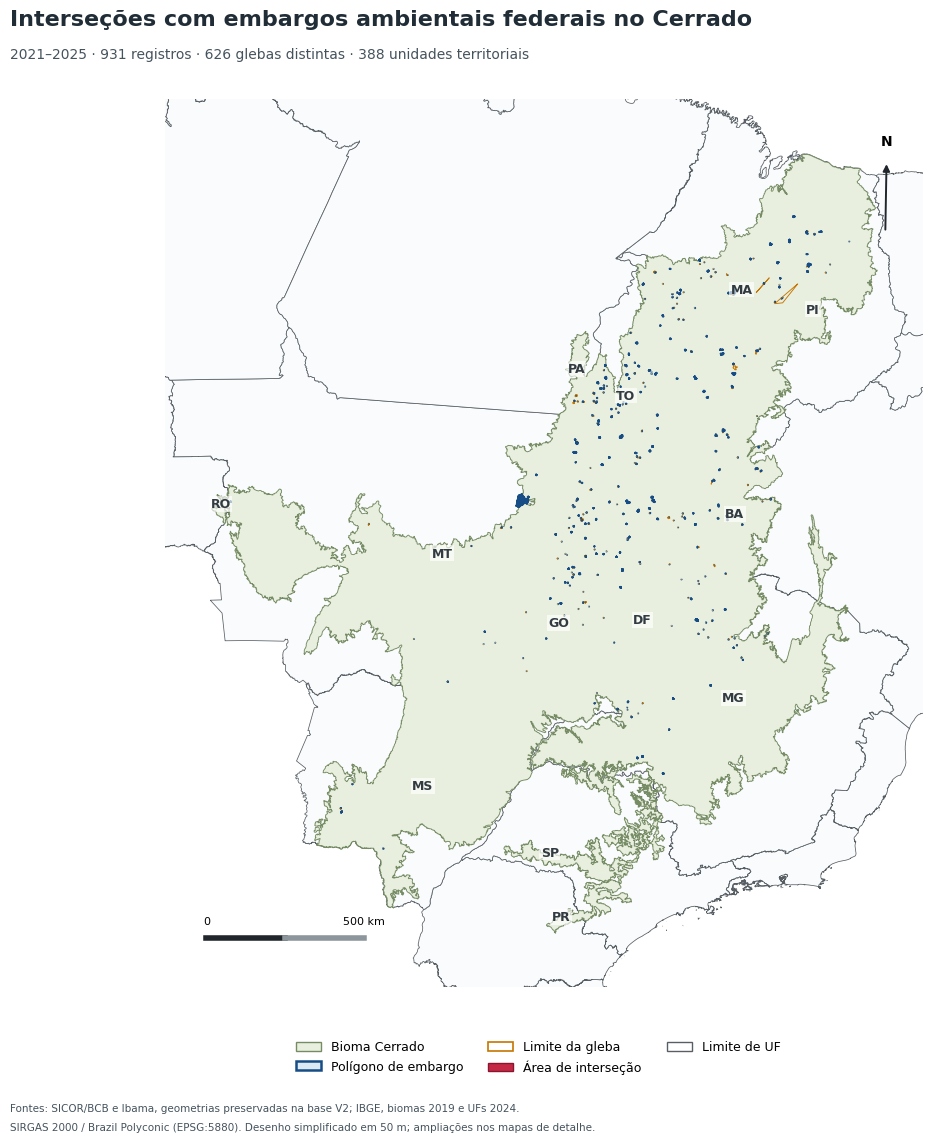

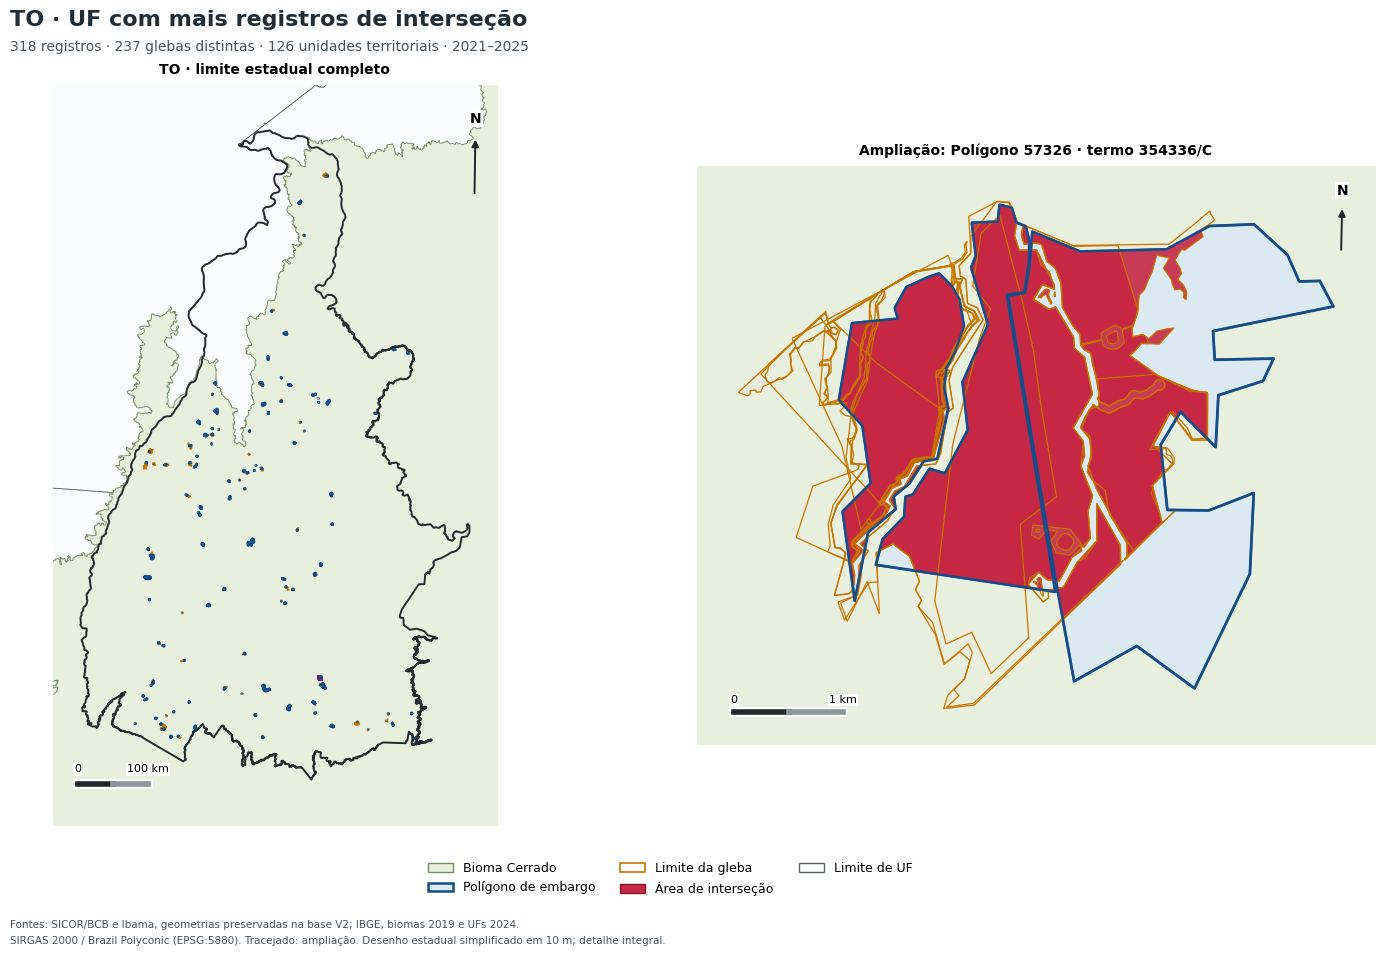

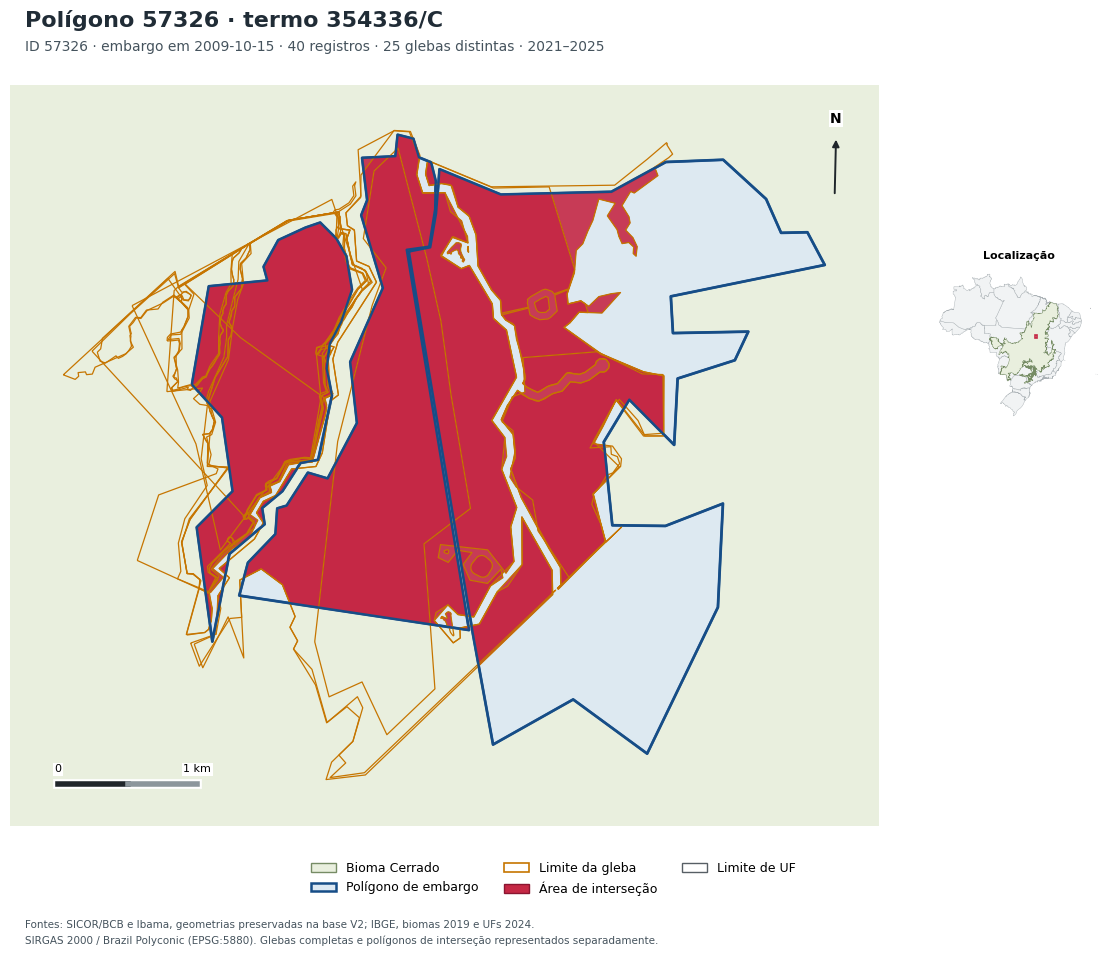

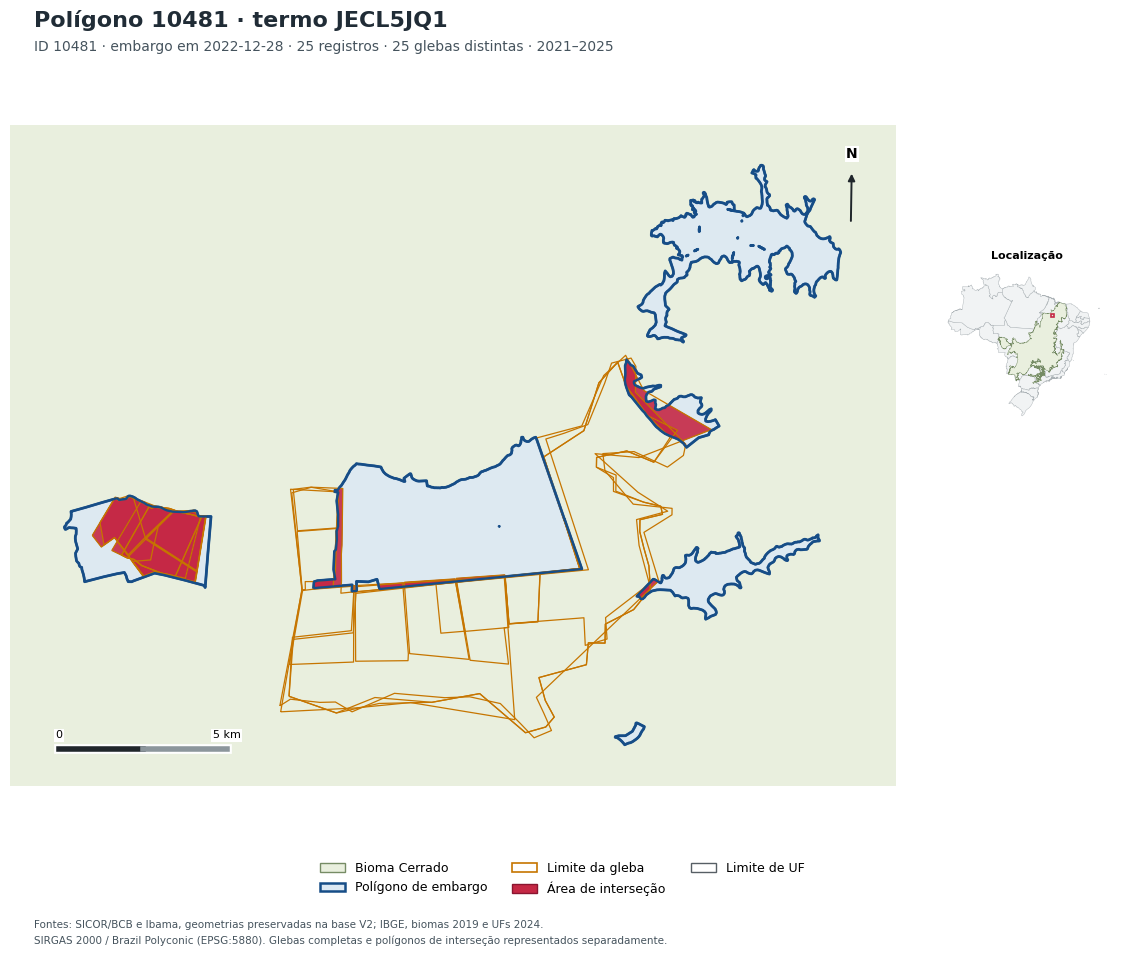

In [9]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titleweight':'bold','savefig.facecolor':'white','svg.fonttype':'none'})
COR_EMBARGO='#164D87';COR_GLEBA='#C67500';COR_INTER='#C52845';COR_CERRADO='#E9EFDE';COR_UF='#575F65'
mapas_gerados=[]
para_ll=Transformer.from_crs(CRS_ANALISE,4674,always_xy=True)
para_xy=Transformer.from_crs(4674,CRS_ANALISE,always_xy=True)
geod=Geod(ellps='GRS80')

def serie(geom):return gpd.GeoSeries([geom],crs=CRS_ANALISE)
def enquadrar(ax,bounds,margem=0.07):
    a,b,c,d=map(float,bounds);w=max(c-a,1000);h=max(d-b,1000)
    ax.set_xlim(a-margem*w,c+margem*w);ax.set_ylim(b-margem*h,d+margem*h)
    ax.set_aspect('equal');ax.set_axis_off()

def perto(z,bounds):
    ids=z.sindex.query(box(*bounds),predicate='intersects')
    return z.iloc[ids]

def adornos(ax):
    a,c=ax.get_xlim();b,d=ax.get_ylim();w=c-a;h=d-b
    # Barra horizontal com comprimento calibrado geodesicamente no local.
    x0=a+0.055*w;y0=b+0.055*h
    lo,la=para_ll.transform(x0,y0);lo2,la2=para_ll.transform(x0+0.23*w,y0)
    _,_,dist=geod.inv(lo,la,lo2,la2)
    exp=10**math.floor(math.log10(max(dist,1)))
    length=max(v for v in [1*exp,2*exp,5*exp,10*exp,0.5*exp] if v<=dist)
    dx=0.23*w*length/dist
    ax.plot([x0,x0+dx],[y0,y0],color='white',lw=7,zorder=30)
    ax.plot([x0,x0+dx/2],[y0,y0],color='#20262B',lw=4,zorder=31)
    ax.plot([x0+dx/2,x0+dx],[y0,y0],color='#8C969C',lw=4,zorder=31)
    txt=f'{length/1000:g} km' if length>=1000 else f'{length:g} m'
    ax.text(x0,y0+0.016*h,'0',fontsize=8,zorder=32,ha='center',bbox=dict(fc='white',ec='none',pad=1))
    ax.text(x0+dx,y0+0.016*h,txt,fontsize=8,zorder=32,ha='center',bbox=dict(fc='white',ec='none',pad=1))
    # Norte verdadeiro no ponto de implantação da seta.
    nx=a+0.95*w;ny=b+0.85*h;lon,lat=para_ll.transform(nx,ny)
    xx,yy=para_xy.transform(lon,lat+0.1);vx=xx-nx;vy=yy-ny;norm=math.hypot(vx,vy)
    ex=nx+vx/norm*h*0.08;ey=ny+vy/norm*h*0.08
    ax.annotate('',xy=(ex,ey),xytext=(nx,ny),arrowprops=dict(arrowstyle='-|>',color='#20262B',lw=1.4),zorder=35)
    ax.text(ex,ey+0.015*h,'N',ha='center',va='bottom',weight='bold',fontsize=10,zorder=35,bbox=dict(fc='white',ec='none',pad=1))

def desenhar(ax,territorio_ids,gleba_ids,ocorrencias,bounds,escala='geral',estado=None):
    a,b,c,d=bounds;w=max(c-a,1000);h=max(d-b,1000)
    janela=box(a-.10*w,b-.10*h,c+.10*w,d+.10*h)
    bg=perto(ufs,janela.bounds).copy()
    bg.geometry=bg.geometry.intersection(janela)
    bg.plot(ax=ax,facecolor='#FAFBFC',edgecolor=COR_UF,linewidth=0.55,zorder=0)
    contexto=cerrado.intersection(janela)
    if not contexto.is_empty:serie(contexto).plot(ax=ax,facecolor=COR_CERRADO,edgecolor='#768C65',linewidth=0.65,zorder=1)
    if escala=='geral':
        ts=territorios.loc[territorios.unidade.isin(territorio_ids)];gs=glebas.loc[glebas.gleba.isin(gleba_ids)]
    else:
        tolerancia=SIMPLIFICACAO_ESTADO_M if escala=='estado' else 0
        ts=carregar_geometrias('territorio',territorio_ids,tolerancia)
        gs=carregar_geometrias('gleba',gleba_ids,tolerancia)
    # Cópias sobrepostas desenhadas uma vez; as contagens continuam usando todas as linhas.
    ocorrencias=ocorrencias[['geometry']].drop_duplicates('geometry').copy()
    if escala in ['geral','estado']:
        tol=SIMPLIFICACAO_GERAL_M if escala=='geral' else SIMPLIFICACAO_ESTADO_M
        ocorrencias.geometry=ocorrencias.geometry.simplify(tol,preserve_topology=True)
    if not ts.empty:ts.plot(ax=ax,facecolor='#DDE9F3',edgecolor=COR_EMBARGO,linewidth=1.5 if escala=='geral' else 2.0,alpha=0.95,zorder=3)
    if not ocorrencias.empty:ocorrencias.plot(ax=ax,facecolor=COR_INTER,edgecolor='#8A1530',linewidth=0.35,alpha=0.90,zorder=5,rasterized=True)
    if not gs.empty:gs.boundary.plot(ax=ax,color=COR_GLEBA,linewidth=0.65 if escala=='geral' else 0.9,zorder=6,rasterized=True)
    # Redesenha o contorno do território sobre as interseções.
    if not ts.empty:ts.boundary.plot(ax=ax,color=COR_EMBARGO,linewidth=1.2 if escala=='geral' else 1.65,zorder=7)
    if estado is not None:serie(estado).boundary.plot(ax=ax,color='#252C31',linewidth=1.4,zorder=7)
    enquadrar(ax,bounds);adornos(ax)

handles=[Patch(facecolor=COR_CERRADO,edgecolor='#768C65',label='Bioma Cerrado'),
         Patch(facecolor='#DDE9F3',edgecolor=COR_EMBARGO,linewidth=1.8,label='Polígono de embargo'),
         Patch(facecolor='none',edgecolor=COR_GLEBA,linewidth=1.2,label='Limite da gleba'),
         Patch(facecolor=COR_INTER,edgecolor='#8A1530',label='Área de interseção'),
         Patch(facecolor='none',edgecolor=COR_UF,linewidth=1,label='Limite de UF')]

def finalizar(fig,nome,titulo,subtitulo,nota=''):
    fig.suptitle(titulo,x=0.06,y=0.965,ha='left',fontsize=16,weight='bold',color='#202C36')
    fig.text(0.06,0.924 if '\n' not in titulo else 0.89,subtitulo,ha='left',fontsize=10,color='#45535D')
    fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(0.5,0.068),ncol=3,frameon=False,fontsize=9)
    fonte='Fontes: SICOR/BCB e Ibama, geometrias preservadas na base V2; IBGE, biomas 2019 e UFs 2024.'
    if ARQUIVO_UFS or ARQUIVO_BIOMAS:fonte='Fontes: SICOR/BCB e Ibama (base V2); '+FONTE_BIOMAS+'; '+FONTE_UFS+'.'
    fig.text(0.06,0.047,fonte,fontsize=7.5,color='#45535D')
    fig.text(0.06,0.031,'SIRGAS 2000 / Brazil Polyconic (EPSG:5880). '+nota,fontsize=7.5,color='#45535D')
    fig.subplots_adjust(left=0.04,right=0.97,bottom=0.15,top=0.89 if '\n' not in titulo else 0.845)
    for ext in FORMATOS:fig.savefig(SAIDA/'mapas'/f'{nome}.{ext}',dpi=DPI)
    mapas_gerados.append({'arquivo':nome,'titulo':titulo,'subtitulo':subtitulo,'nota':nota})
    if MOSTRAR_FIGURAS:plt.show()
    plt.close(fig)

fig,ax=plt.subplots(figsize=(12,12))
desenhar(ax,territorios.unidade,glebas.gleba,x,cerrado.bounds)
for _,u in ufs.loc[ufs.intersects(cerrado)].iterrows():
    pt=u.geometry.intersection(cerrado).representative_point()
    ax.text(pt.x,pt.y,u.UF,fontsize=9,weight='bold',color='#323B41',ha='center',zorder=20,
            bbox=dict(fc='white',ec='none',alpha=0.65,pad=1))
finalizar(fig,'01_cerrado_embargos_contornos_reforcados','Interseções com embargos ambientais federais no Cerrado',
          f"2021–2025 · {len(x):,} registros · {len(glebas):,} glebas distintas · {len(territorios)} unidades territoriais".replace(',','.'),
          f'Desenho simplificado em {SIMPLIFICACAO_GERAL_M} m; ampliações nos mapas de detalhe.')

# Estado completo à esquerda e ampliação do território com mais registros nesse estado à direita.
z=xuf.loc[xuf.UF.eq(UF_TOP)].copy();estado=ufs.loc[ufs.UF.eq(UF_TOP)].geometry.iloc[0]
rank_local=z.groupby('unidade').linha.nunique().rename('n').reset_index().merge(territorios[['unidade','nome']],on='unidade')
top_local=rank_local.sort_values(['n','nome','unidade'],ascending=[False,True,True]).iloc[0].unidade
zl=z.loc[z.unidade.eq(top_local)];territorio_local=carregar_geometrias('territorio',[top_local]).iloc[0]
gl_local=carregar_geometrias('gleba',zl.gleba)
bdet=gpd.GeoSeries([territorio_local.geometry,*gl_local.geometry],crs=CRS_ANALISE).total_bounds
fig,axs=plt.subplots(1,2,figsize=(15,10),gridspec_kw={'width_ratios':[1,1.15]})
desenhar(axs[0],z.unidade.unique(),z.gleba.unique(),z,estado.bounds,'estado',estado)
desenhar(axs[1],[top_local],zl.gleba.unique(),zl,bdet,'detalhe',estado)
axs[0].set_title(f'{UF_TOP} · limite estadual completo',fontsize=10,pad=8)
axs[1].set_title('Ampliação: '+'\n'.join(textwrap.wrap(territorio_local['nome'],width=44)),fontsize=10,pad=8)
a,b,c,e=bdet;axs[0].add_patch(Rectangle((a,b),c-a,e-b,fill=False,edgecolor='#5B296F',linewidth=1.4,linestyle='--',zorder=25))
finalizar(fig,'02_uf_mais_casos_com_ampliacao',f'{UF_TOP} · UF com mais registros de interseção',
          f'{z.linha.nunique()} registros · {z.gleba.nunique()} glebas distintas · {z.unidade.nunique()} unidades territoriais · 2021–2025',
          f'Tracejado: ampliação. Desenho estadual simplificado em {SIMPLIFICACAO_ESTADO_M} m; detalhe integral.')

for pos,ident in enumerate(TOP_TERRITORIOS,1):
    t=carregar_geometrias('territorio',[ident]).iloc[0];zi=x.loc[x.unidade.eq(ident)]
    gi=carregar_geometrias('gleba',zi.gleba)
    limites=gpd.GeoSeries([t.geometry,*gi.geometry],crs=CRS_ANALISE).total_bounds
    fig=plt.figure(figsize=(12,10));ax=fig.add_subplot(1,5,(1,4))
    desenhar(ax,[ident],gi.gleba,zi,limites,'detalhe')
    # Limites estaduais, quando presentes no enquadramento, sempre visíveis.
    limites_uf=perto(ufs,limites).boundary.intersection(box(*limites))
    limites_uf=limites_uf.loc[~limites_uf.is_empty]
    if not limites_uf.empty:limites_uf.plot(ax=ax,color='#252C31',linewidth=0.8,zorder=7)
    # Miniatura em espaço próprio, fora do mapa principal e da seta norte.
    # O painel principal de detalhe utiliza as geometrias integrais.
    en=fig.add_axes([0.815,0.50,0.145,0.26])
    ufs.geometry.simplify(1500,preserve_topology=True).plot(ax=en,facecolor='#F1F3F4',edgecolor='#AAB1B5',linewidth=0.3)
    serie(cerrado.simplify(1500,preserve_topology=True)).plot(ax=en,facecolor=COR_CERRADO,edgecolor='#768C65',linewidth=0.3)
    # Retângulo de localização no Brasil; não representa a área da gleba.
    a,b,c,e=limites;en.add_patch(Rectangle((a,b),max(c-a,80000),max(e-b,80000),fill=False,edgecolor=COR_INTER,linewidth=1.2))
    en.set_axis_off();en.set_title('Localização',fontsize=8)
    m=por_territorio.loc[por_territorio.unidade.eq(ident)].iloc[0]
    titulo='\n'.join(textwrap.wrap(t['nome'],width=62))
    finalizar(fig,f'{pos+2:02d}_embargo_{re.sub(r"[^A-Za-z0-9_-]","_",str(ident))}_detalhe',titulo,
       f"ID {ident} · embargo em {t.data_embargo} · {m.registros} registros · {m.glebas} glebas distintas · 2021–2025",
       'Glebas completas e polígonos de interseção representados separadamente.')


## 10. Manter os gráficos e o mapa da análise temporal

São produzidos o gráfico das quatro classes, o gráfico anual e o mapa com pontos internos às geometrias de interseção. Pontos coincidentes podem se sobrepor; o número de pontos visíveis não substitui a contagem de registros. Os rótulos abreviados das figuras correspondem às classificações literais exportadas nas tabelas.

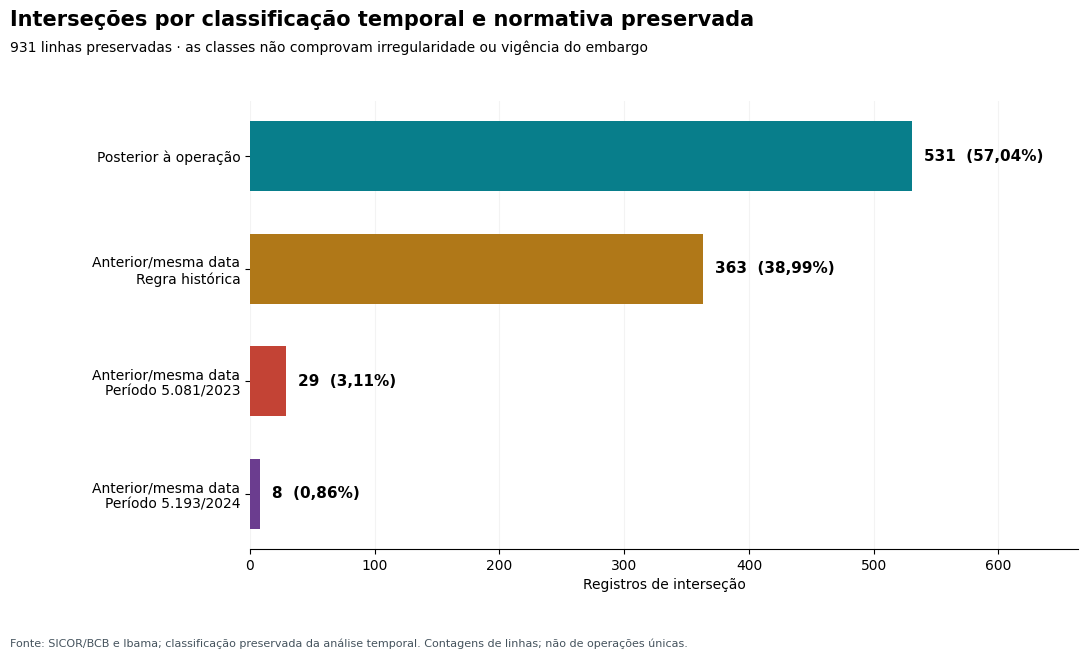

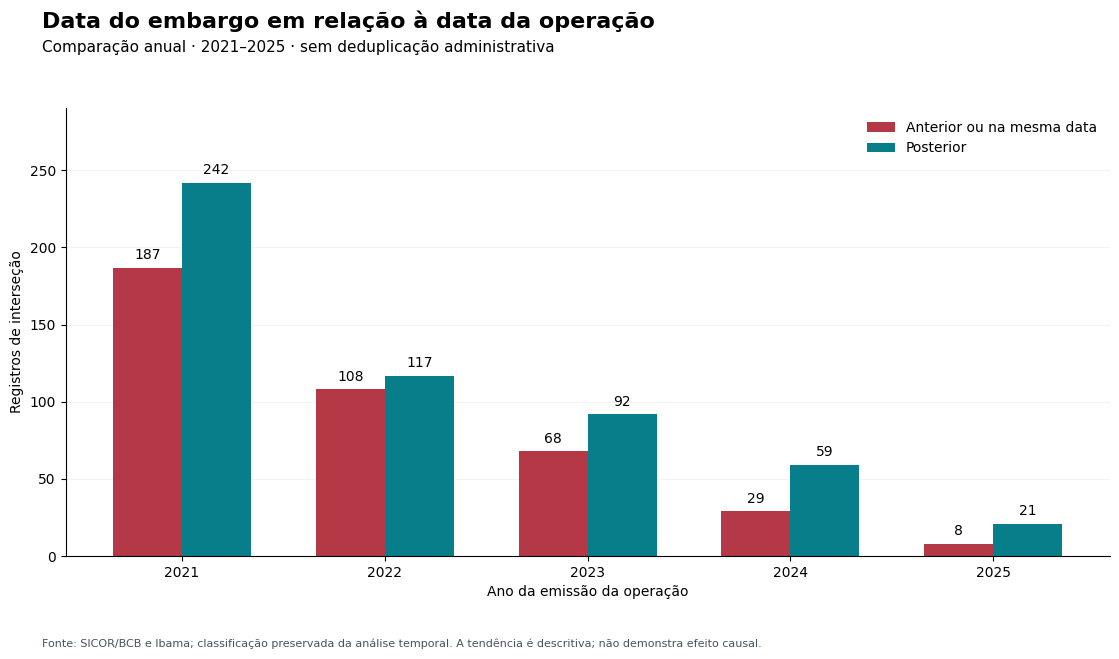

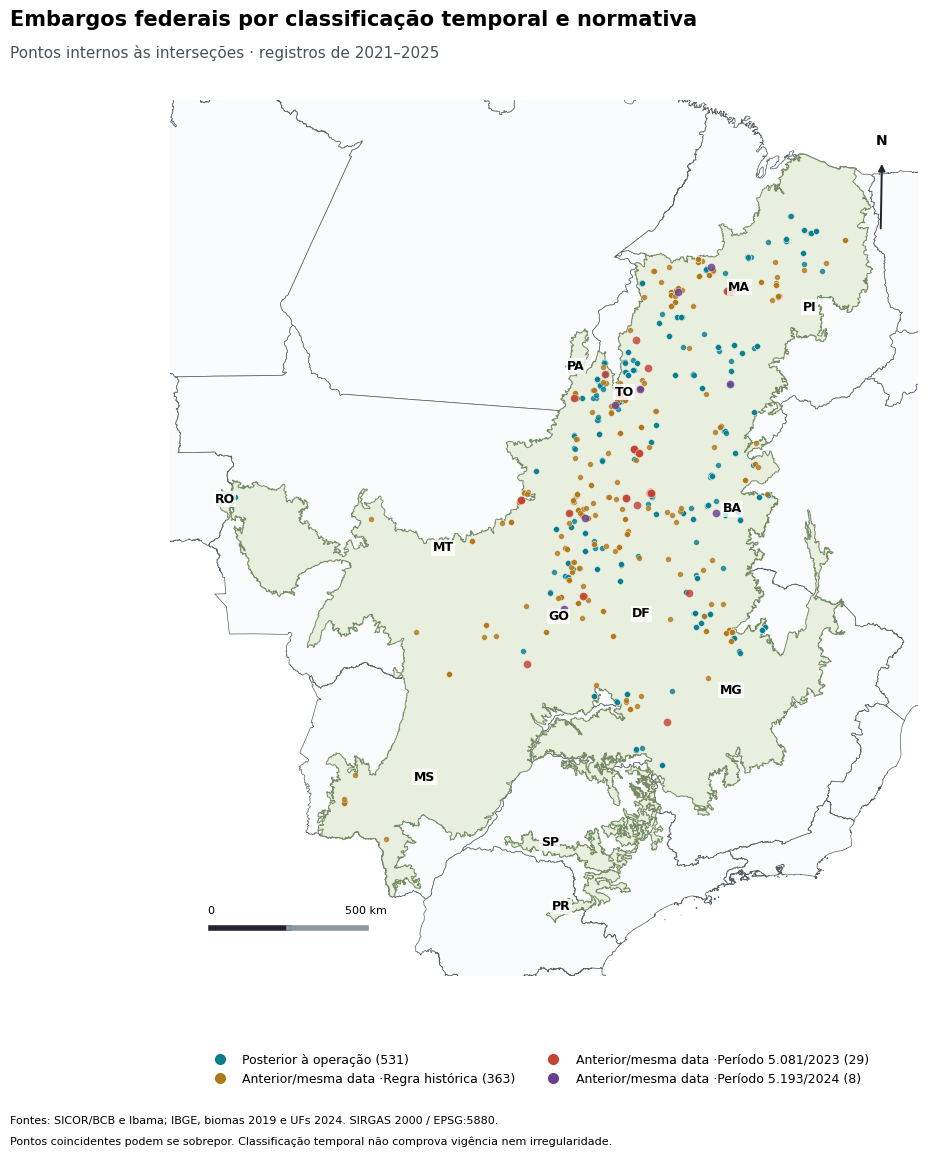

In [10]:
graficos_gerados=[]
def br(v,casas=0):return f'{float(v):,.{casas}f}'.replace(',','X').replace('.',',').replace('X','.')
def salvar_grafico(fig,nome,titulo,nota):
 fig.text(.07,.04,'Fonte: SICOR/BCB e Ibama; classificação preservada da análise temporal. '+nota,fontsize=8,color='#45535D')
 for ext in FORMATOS:fig.savefig(SAIDA/'graficos'/f'{nome}.{ext}',dpi=DPI)
 graficos_gerados.append({'arquivo':nome,'titulo':titulo,'nota':nota})
 if MOSTRAR_FIGURAS:plt.show()
 plt.close(fig)

fig,ax=plt.subplots(figsize=(12,7))
vals=por_classe.set_index('classificacao').reindex(CLASSES).registros
pos=np.arange(4)
ax.barh(pos,vals,color=CORES_CLASSES,height=.62)
ax.set_yticks(pos,ROTULOS_CURTOS);ax.invert_yaxis();ax.set_xlim(0,float(vals.max())*1.25)
for i,v in enumerate(vals):ax.text(v+float(vals.max())*.018,i,f'{br(v)}  ({br(v/len(x)*100,2)}%)',va='center',fontsize=11,weight='bold')
ax.set_xlabel('Registros de interseção');ax.spines[['top','right','left']].set_visible(False);ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
fig.suptitle('Interseções por classificação temporal e normativa preservada',x=.07,y=.95,ha='left',fontsize=15,weight='bold')
fig.text(.07,.89,'931 linhas preservadas · as classes não comprovam irregularidade ou vigência do embargo',fontsize=10)
fig.subplots_adjust(left=.27,right=.96,top=.82,bottom=.18)
salvar_grafico(fig,'01_classificacao_temporal_normativa','Interseções por classificação temporal e normativa preservada','Contagens de linhas; não de operações únicas.')

fig,ax=plt.subplots(figsize=(12,7));pos=np.arange(len(ANOS));w=.34
for off,col,cor,lab in [(-w/2,ANT,'#B43845','Anterior ou na mesma data'),(w/2,POST,'#087E8B','Posterior')]:
 bars=ax.bar(pos+off,matriz[col].values,width=w,label=lab,color=cor)
 ax.bar_label(bars,padding=4,fontsize=10)
ax.set_xticks(pos,ANOS);ax.set_xlabel('Ano da emissão da operação');ax.set_ylabel('Registros de interseção')
ax.set_ylim(0,matriz.max().max()*1.2);ax.spines[['top','right']].set_visible(False);ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
ax.legend(frameon=False,loc='upper right')
fig.suptitle('Data do embargo em relação à data da operação',x=.07,y=.95,ha='left',fontsize=16,weight='bold')
fig.text(.07,.89,'Comparação anual · 2021–2025 · sem deduplicação administrativa',fontsize=11)
fig.subplots_adjust(left=.09,right=.96,top=.81,bottom=.17)
salvar_grafico(fig,'02_relacao_temporal_por_ano','Relação temporal entre embargo e operação, por ano','A tendência é descritiva; não demonstra efeito causal.')

# Mapa adicional mantém a análise anterior por classe, com posições internas às interseções.
fig,ax=plt.subplots(figsize=(12,12))
ufs.plot(ax=ax,facecolor='#FAFBFC',edgecolor=COR_UF,linewidth=.5)
serie(cerrado).plot(ax=ax,facecolor=COR_CERRADO,edgecolor='#768C65',linewidth=.7)
points=x.geometry.representative_point()
for i,classe in enumerate(CLASSES):
 mask=x.classificacao.eq(classe);pontos=points.loc[mask]
 ax.scatter(pontos.x,pontos.y,s=18 if i<2 else 35,c=CORES_CLASSES[i],edgecolors='white',linewidths=.3,alpha=.82,zorder=4+i)
enquadrar(ax,cerrado.bounds);adornos(ax)
for _,u in ufs.loc[ufs.intersects(cerrado)].iterrows():
 pt=u.geometry.intersection(cerrado).representative_point();ax.text(pt.x,pt.y,u.UF,fontsize=9,weight='bold',ha='center',zorder=15,bbox=dict(fc='white',ec='none',alpha=.8,pad=1))
fig.suptitle('Embargos federais por classificação temporal e normativa',x=.06,y=.965,ha='left',fontsize=15,weight='bold')
fig.text(.06,.925,'Pontos internos às interseções · registros de 2021–2025',fontsize=11,color='#45535D')
hs=[Line2D([0],[0],marker='o',linestyle='',color=cor,label=lab.replace('\n',' ·')+' ('+str(int(v))+')',markersize=7) for cor,lab,v in zip(CORES_CLASSES,ROTULOS_CURTOS,vals)]
fig.legend(handles=hs,loc='lower center',bbox_to_anchor=(.5,.059),ncol=2,frameon=False,fontsize=9)
fig.text(.06,.037,'Fontes: SICOR/BCB e Ibama; IBGE, biomas 2019 e UFs 2024. SIRGAS 2000 / EPSG:5880.',fontsize=8)
fig.text(.06,.019,'Pontos coincidentes podem se sobrepor. Classificação temporal não comprova vigência nem irregularidade.',fontsize=8)
fig.subplots_adjust(left=.04,right=.97,top=.89,bottom=.16)
for ext in FORMATOS:fig.savefig(SAIDA/'mapas'/f'05_cerrado_classificacao_temporal_normativa.{ext}',dpi=DPI)
mapas_gerados.append({'arquivo':'05_cerrado_classificacao_temporal_normativa','titulo':'Embargos federais por classificação temporal e normativa preservada','subtitulo':'Pontos internos às interseções; 2021–2025','nota':'Pode haver sobreposição de pontos; as contagens mantêm todas as linhas.'})
if MOSTRAR_FIGURAS:plt.show()
plt.close(fig)


## 11. Exportar as tabelas, legendas e a síntese para o subcapítulo

In [11]:
# Planilhas e tabelas editáveis. Nenhuma célula é interpretada como fórmula do Excel.
TABELAS.update({'Qualidade temporal':qualidade_temporal,'Conferencia global':conferencia,
 'Conferencia classes':controle_classes,'Conferencia prioritarios':controle_prioritarios,
 'Conferencia datas':qualidade_datas,'Vinculo temporal V2':controle_identidade,
 'Geometrias V2 temporal':conferencia_copias,'Reparos desenho':reparos})
excel=SAIDA/'tabelas'/'Totais_Embargos_5_5_5.xlsx'
with pd.ExcelWriter(excel,engine='openpyxl') as writer:
 for nome,df in TABELAS.items():df.to_excel(writer,sheet_name=nome[:31],index=False)
 from openpyxl.styles import Font,PatternFill,Alignment
 for ws in writer.book.worksheets:
  ws.freeze_panes='A2';ws.auto_filter.ref=ws.dimensions
  for cell in ws[1]:cell.font=Font(bold=True,color='FFFFFF');cell.fill=PatternFill('solid',fgColor='214C65');cell.alignment=Alignment(wrap_text=True,vertical='center')
  ws.row_dimensions[1].height=38
  for cells in ws.columns:
   head=cells[0].value or '';ws.column_dimensions[cells[0].column_letter].width=45 if any(s in head for s in ['nome','class','observ','periodo']) else 23
   for cell in cells[1:]:
    if cell.data_type=='f':cell.data_type='s'
    if isinstance(cell.value,float):cell.number_format='#,##0.00'
    cell.alignment=Alignment(vertical='top',wrap_text=isinstance(cell.value,str) and len(cell.value)>40)

cabecalhos={'unidade':'ID do polígono','termo':'Termo','serie':'Série','uf_territorio':'UF do atributo',
 'municipio_atributo':'Município do atributo','registros':'Registros','glebas':'Glebas distintas','refs':'REF_BACEN distintos',
 'area_acumulada_ha':'Área acumulada (ha)','area_uniao_ha':'União geométrica (ha)','soma_valores_linhas':'Valor somado nas linhas (R$)',
 'registros_anterior_ou_mesma_data':'Anterior ou mesma data','registros_posterior':'Posterior','registros_prioritarios_desde_2024':'Prioritários desde 2024'}
cols=list(cabecalhos)
for nome,df in [('tabela_completa_por_embargo',por_territorio),('tabela_20_embargos',por_territorio.head(20))]:
 tb=df[cols].copy()
 for c in cols:
  if c in ['registros','glebas','refs','registros_anterior_ou_mesma_data','registros_posterior','registros_prioritarios_desde_2024']:tb[c]=tb[c].map(br)
  elif c in ['area_acumulada_ha','area_uniao_ha']:tb[c]=tb[c].map(lambda v:br(v,6))
  elif c=='soma_valores_linhas':tb[c]=tb[c].map(lambda v:br(v,2))
 html='<!doctype html><html lang="pt-br"><meta charset="utf-8"><style>body{font-family:Arial;margin:28px}table{border-collapse:collapse}td,th{border:1px solid #ccd2d6;padding:7px}th{background:#e9eef2}</style>'
 html+='<h1>Totais por polígono de embargo — Cerrado, 2021–2025</h1>'+tb.rename(columns=cabecalhos).to_html(index=False,escape=True)
 html+='<p>Fonte: SICOR/BCB, Ibama e processamento complementar. Identificação pelo EMB_ID_INTERNO; termo não substitui o ID do polígono. Glebas, referências e uniões por unidade não são aditivas. Datas e classificações não comprovam vigência. As áreas com seis casas decimais tornam visíveis pequenas interseções, sem representar precisão posicional.</p></html>'
 (SAIDA/'tabelas'/f'{nome}.html').write_text(html,encoding='utf-8')
matriz.reset_index().to_html(SAIDA/'tabelas'/'tabela_relacao_anual.html',index=False)
resumo=[f"Foram preservados {br(geral['registros'])} registros, {br(geral['glebas'])} glebas distintas, {br(geral['territorios'])} polígonos e {br(geral['refs'])} referências BACEN.",
 f"Área acumulada: {br(geral['area_acumulada_ha'],2)} ha; união: {br(geral['area_uniao_ha'],2)} ha; valor somado nas linhas: R$ {br(geral['soma_valores_linhas'],2)}.",
 f"Datas válidas: {len(x)}; anterior ou mesma data: {int(x.relacao_temporal.eq(ANT).sum())}; posterior: {int(x.relacao_temporal.eq(POST).sum())}; mesma data: {int(x.mesma_data.sum())}.",
 f"Prioritários desde 02/01/2024: {resumo_prioritarios['registros']} registros; R$ {br(resumo_prioritarios['soma_valores_linhas'],2)} somados nas linhas; {br(resumo_prioritarios['area_acumulada_ha'],2)} ha acumulados; {br(resumo_prioritarios['area_uniao_ha'],2)} ha de união.",
 f"UF com mais registros: {UF_TOP}, {br(por_uf.iloc[0].registros)}. Soma estadual: {br(por_uf.registros.sum())}; {len(linhas_multiuf)} linhas alcançam mais de uma UF.",
 'Polígonos selecionados pelo maior número de registros:']
for ident in TOP_TERRITORIOS:
 r=por_territorio.loc[por_territorio.unidade.eq(ident)].iloc[0]
 resumo.append(f"- {r['nome']}; UF do atributo {r.uf_territorio}; {br(r.registros)} registros, {br(r.glebas)} glebas, {br(r.refs)} referências; {br(r.area_acumulada_ha,2)} ha acumulados e {br(r.area_uniao_ha,2)} ha de união. Anterior/mesma data: {br(r.registros_anterior_ou_mesma_data)}; posterior: {br(r.registros_posterior)}.")
resumo+=['','Resultados municipais da V2 preservados, sem novo recálculo municipal:']
for _,r in municipios_v2.head(3).iterrows():resumo.append(f"- {r.MUNICIPIO}/{r.UF}: {br(r.AREA_FISICA_UNICA_HA,2)} ha de união.")
resumo+=['','As quatro classes da análise temporal anterior foram preservadas. Não houve reavaliação jurídica nem confirmação da vigência de cada embargo.',
 'Embargo posterior significa que a data registrada é posterior à emissão da operação, sem afastar outras restrições ou eventos não representados na base.',
 'Os 400 registros anteriores ou na mesma data e os 37 prioritários não são contagens de concessões irregulares. Valores financeiros podem se repetir e não foram rateados pela área intersectada.',
 'As diferenças estaduais em relação à V2 estão documentadas: as UFs atuais usam o recorte direto das interseções pela malha de 2024.',
 f"Reparos exclusivos do desenho: {len(reparos)}. Cópias temporais inválidas na origem: {int((~conferencia_copias.copia_temporal_valida_origem).sum())}; a fonte geométrica dos cálculos é a V2."]
(SAIDA/'resultados_para_reescrita_5_5_5.txt').write_text('\n\n'.join(resumo),encoding='utf-8')
legendas=[]
for item in mapas_gerados+graficos_gerados:legendas.append(item['arquivo']+'\n'+item['titulo']+' — Cerrado, operações de 2021–2025.\nFonte: elaborado pelo autor com dados do SICOR/BCB e do Ibama; IBGE para o contexto cartográfico.\nNota: '+item['nota'])
(SAIDA/'legendas_das_figuras.txt').write_text('\n\n'.join(legendas),encoding='utf-8')
print('\n\n'.join(resumo))


Foram preservados 931 registros, 626 glebas distintas, 388 polígonos e 570 referências BACEN.

Área acumulada: 25.299,09 ha; união: 11.122,34 ha; valor somado nas linhas: R$ 1.392.013.462,24.

Datas válidas: 931; anterior ou mesma data: 400; posterior: 531; mesma data: 0.

Prioritários desde 02/01/2024: 37 registros; R$ 118.918.292,80 somados nas linhas; 1.532,41 ha acumulados; 982,04 ha de união.

UF com mais registros: TO, 318. Soma estadual: 932; 1 linhas alcançam mais de uma UF.

Polígonos selecionados pelo maior número de registros:

- Polígono 57326 · termo 354336/C; UF do atributo TO; 40 registros, 25 glebas, 10 referências; 4.360,32 ha acumulados e 726,21 ha de união. Anterior/mesma data: 40; posterior: 0.

- Polígono 10481 · termo JECL5JQ1; UF do atributo MA; 25 registros, 25 glebas, 5 referências; 2.807,56 ha acumulados e 837,15 ha de união. Anterior/mesma data: 4; posterior: 21.



Resultados municipais da V2 preservados, sem novo recálculo municipal:

- Formosa do Rio Preto

## 12. Registrar as fontes e gerar o ZIP

In [12]:
metadados={'execucao_utc':datetime.now(timezone.utc).isoformat(),'origens':ORIGENS,'crs_wkt':CRS_WKT,'crs_calculo':CRS_ANALISE,
 'colunas_espaciais':C,'colunas_temporais':CT,'totais':geral,'deduplicacao_analitica':False,
 'classificacao':'Preservada literalmente da análise temporal existente; recortes conferidos, sem nova qualificação jurídica',
 'geometria_analitica':'V2; as cópias do arquivo temporal são apenas comparadas e auditadas',
 'prioritarios':resumo_prioritarios,'uf_selecionada':UF_TOP,'poligonos_selecionados':TOP_TERRITORIOS,
 'criterio_selecao':'Maior número de registros; desempate por nome/ID ou sigla da UF',
 'mapas':mapas_gerados,'graficos':graficos_gerados,'reparos_desenho':REPAROS_CARTOGRAFICOS,
 'corte_estadual_diferenca_ha':residuo,'linhas_em_mais_de_uma_uf':len(linhas_multiuf),
 'municipios':'Resultado espacial V2 preservado, não recalculado',
 'versoes':{'python':platform.python_version(),'pandas':pd.__version__,'geopandas':gpd.__version__,'shapely':shapely.__version__}}
(SAIDA/'metadados.json').write_text(json.dumps(metadados,ensure_ascii=False,indent=2),encoding='utf-8')
zip_path=SAIDA/'Resultados_Embargos_5_5_5.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
 for p in sorted(SAIDA.rglob('*')):
  if p.is_file() and p!=zip_path:z.write(p,p.relative_to(SAIDA))
print('Resultados:',SAIDA);print('ZIP:',zip_path)
if BAIXAR_ZIP:
 try:
  from google.colab import files
  files.download(str(zip_path))
 except ImportError:print('Fora do Colab: use o ZIP na pasta dos resultados.')


Resultados: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_embargos_5_5_5/20260918_142715_010681
ZIP: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_embargos_5_5_5/20260918_142715_010681/Resultados_Embargos_5_5_5.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### O que compartilhar depois da execução

Envie o ZIP `Resultados_Embargos_5_5_5.zip` ou o caminho da pasta que aparece ao final. Ela contém as tabelas completas, os sete produtos visuais e os resultados necessários à reescrita do 5.5.5.

**Como interpretar:** os 37 registros prioritários são um subconjunto para exame documental, não uma contagem de operações irregulares. `False` em vigência confirmada significa ausência de confirmação automática, e não prova de que o embargo estava inativo. A redução anual é descritiva e não demonstra efeito causal de mudanças normativas.
